# Lab 1-03：用 OpenAI SDK 跟模型對話

**目標**：用官方 `openai` SDK 連本機 Ollama 跟模型對話，看一次回應的原始 JSON，
再走過 system 訊息、溫度、「記不住對話」、字數上限、串流這幾個每天都會碰到的事。

**你會學到**
- Chat API 的請求只是一個 `messages` 陣列
- system / user / assistant 三種角色各管什麼
- 為什麼模型記不住上一句：記憶是你每次重送的，而且越聊越貴
- `finish_reason` 和串流怎麼用

**前置**：先讀 `00_concepts.md` 第 6 節（為什麼模型記不住對話）。本機裝好 [Ollama](https://ollama.com/download)，並在終端機執行：

```bash
ollama pull qwen2.5:3b
```

想改用雲端，只要在 `.env` 改 `LOCAL_BASE_URL`、`LOCAL_MODEL`（下一本會做自動切換）。

**對應投影片**：「messages JSON 實物」「為什麼記不住對話」「溫度只管隨機性」

![模型不記得對話：第 1 次請求只送一句，第 2 次請求要把整段歷史一起重送](images/stateless_requests.jpg)

*圖：模型是一個函式，輸入 messages、輸出下一段字，兩次呼叫之間什麼都不留。「記憶」是呼叫端每次把整段歷史一起送出去。*

## Step 1：建立 client

Ollama 提供跟 OpenAI 一樣格式的端點（`/v1/...`），所以用 OpenAI 的 SDK、把 `base_url` 指到本機就能連。
本機不需要金鑰，`api_key` 隨便填一個字串即可。之後換成雲端服務，程式碼不用改，只換網址和金鑰。

In [1]:
import json
import os

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
BASE_URL = os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1")
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")

client = OpenAI(base_url=BASE_URL, api_key="ollama")
print("本機有的模型：", [m.id for m in client.models.list()])
print("這本 notebook 用：", MODEL)

本機有的模型： ['bge-m3:latest', 'qwen2.5:3b']
這本 notebook 用： qwen2.5:3b


## Step 2：一次呼叫，看一次原始 JSON

請求就是：要用哪個模型、對話內容 `messages`、還有幾個抽樣參數。
SDK 回傳的是 Python 物件；`model_dump()` 把它攤回 JSON，看清楚伺服器實際回了什麼。這件事做一次就夠了。

In [2]:
resp = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "用一句話介紹魯夫。"}],
    temperature=0,
)
print(json.dumps(resp.model_dump(exclude_none=True), ensure_ascii=False, indent=2))

{
  "id": "chatcmpl-991",
  "choices": [
    {
      "finish_reason": "stop",
      "index": 0,
      "message": {
        "content": "魯夫是《海賊王》中的主要角色之一，以其智慧和正义感著称。",
        "role": "assistant"
      }
    }
  ],
  "created": 1795017312,
  "model": "qwen2.5:3b",
  "object": "chat.completion",
  "system_fingerprint": "fp_ollama",
  "usage": {
    "completion_tokens": 23,
    "prompt_tokens": 36,
    "total_tokens": 59,
    "prompt_tokens_details": {
      "cached_tokens": 24
    }
  }
}


回應裡要看三個地方：
- `choices[0].message.content`：模型的回答
- `choices[0].finish_reason`：`stop` 是自己講完，`length` 是被字數上限切斷
- `usage`：這次用了多少 token（雲端服務就是照這個收費）

In [3]:
print("回答：", resp.choices[0].message.content)
print("結束原因：", resp.choices[0].finish_reason)
print("token 用量：", resp.usage.prompt_tokens, "進 +", resp.usage.completion_tokens, "出")

回答： 魯夫是《海賊王》中的主要角色之一，以其智慧和正义感著称。
結束原因： stop
token 用量： 36 進 + 23 出


小模型對海賊王的了解很有限，回答很可能是錯的。這不是程式的問題，是上一本講的幻覺；模組 3 的 RAG 會處理它。

包一個小函式，後面方便用。

In [4]:
def say(messages: list[dict], temperature: float = 0, **extra) -> str:
    r = client.chat.completions.create(model=MODEL, messages=messages, temperature=temperature, **extra)
    return r.choices[0].message.content

## Step 3：system message 設定角色與規則

`system` 放的是「整段對話都要遵守」的指示；`user` 是這一輪的問題。

In [5]:
question = {"role": "user", "content": "今天天氣如何？"}

print("--- 沒有 system")
print(say([question]))

print("--- 有 system")
print(say([
    {"role": "system", "content": "你是草帽海賊團的航海士娜美。回答一律不超過兩句，語氣直接。"},
    question,
]))

--- 沒有 system
我很抱歉，由于我是一个云端存在的模型，我没有直接获取实时天气信息的功能。我无法提供你所在地区的具体天气情况。你可以查阅当地的天气预报或者使用相关的天气应用查看。如果你告诉我你所在的城市，我可以提供一些建议来帮助你查找天气信息。
--- 有 system
今天風勢不小，有點偏南。


## Step 4：溫度——同一題問三次

In [6]:
msg = [{"role": "user", "content": "幫草帽海賊團的新船取一個名字，只回名字。"}]
for T in [0, 1.2]:
    print(f"T = {T}：", [say(msg, temperature=T) for _ in range(3)])

T = 0： ['海賊之風', '海賊之風', '海賊之風']
T = 1.2： ['红心万事如意号', '自由之翼', '雷利戰艦']


T = 0 三次幾乎一樣；T 調高，每次都不同。要輸出 JSON 或 SQL 時，溫度一律設 0。

## Step 5：模型記不住你

先告訴它名字，下一個請求再問。

In [7]:
print(say([{"role": "user", "content": "我叫索隆，請記住。"}]))
print("---")
print(say([{"role": "user", "content": "我叫什麼名字？"}]))

好的，我會記住你叫索隆。有什么我可以帮助你解答或讨论的吗？无论是关于你的问题，还是其他你感兴趣的话题，我都很乐意交谈。
---
您目前还没有告诉我您的名字，您可以告诉我，您可以称呼我为Qwen。


第二次請求裡根本沒有名字，模型當然不知道。模型是一個函式：輸入 messages、輸出下一段字，**兩次呼叫之間什麼都不留**。

「記憶」其實是你把整段歷史一起重送：

In [8]:
history = [{"role": "user", "content": "我叫索隆，請記住。"}]
history.append({"role": "assistant", "content": say(history)})
history.append({"role": "user", "content": "我叫什麼名字？"})
print(say(history))
print("這次送出的 messages：")
print(json.dumps(history, ensure_ascii=False, indent=2))

你叫索隆。
這次送出的 messages：
[
  {
    "role": "user",
    "content": "我叫索隆，請記住。"
  },
  {
    "role": "assistant",
    "content": "好的，我會記住你叫索隆。有什么我可以帮助你解答或讨论的吗？无论是关于你的问题，还是其他你感兴趣的话题，我都很乐意交谈。"
  },
  {
    "role": "user",
    "content": "我叫什麼名字？"
  }
]


## Step 6：越聊越貴——看 `usage` 怎麼長

每一輪都要重送整段歷史，所以 `prompt_tokens` 會一路往上疊。連問五輪，把每輪的用量畫出來。

第 1 輪：送出 41 token，回答 26 token
第 2 輪：送出 82 token，回答 68 token
第 3 輪：送出 165 token，回答 80 token
第 4 輪：送出 262 token，回答 80 token
第 5 輪：送出 359 token，回答 39 token


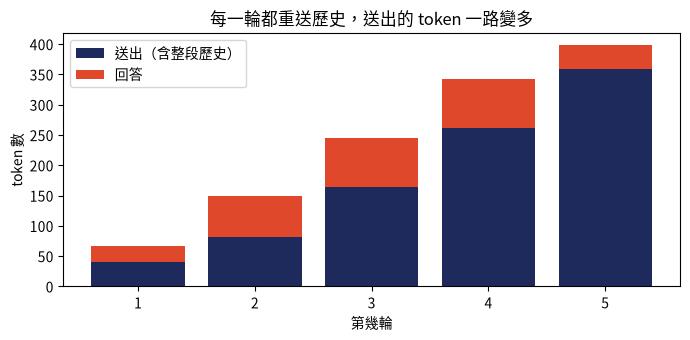

In [9]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()
turns = ["草帽海賊團的船長是誰？", "他吃了什麼果實？", "他的夢想是什麼？", "船上的劍士是誰？", "把以上整理成一句話。"]
chat_log, prompt_used, completion_used = [], [], []
for q in turns:
    chat_log.append({"role": "user", "content": q})
    r = client.chat.completions.create(model=MODEL, messages=chat_log, temperature=0, max_tokens=80)
    chat_log.append({"role": "assistant", "content": r.choices[0].message.content})
    prompt_used.append(r.usage.prompt_tokens)
    completion_used.append(r.usage.completion_tokens)
    print(f"第 {len(prompt_used)} 輪：送出 {r.usage.prompt_tokens} token，回答 {r.usage.completion_tokens} token")

x = range(1, len(turns) + 1)
plt.figure(figsize=(7, 3.5))
plt.bar(x, prompt_used, color="#1f2a5c", label="送出（含整段歷史）")
plt.bar(x, completion_used, bottom=prompt_used, color="#e0482c", label="回答")
plt.xlabel("第幾輪")
plt.ylabel("token 數")
plt.title("每一輪都重送歷史，送出的 token 一路變多")
plt.legend()
plt.tight_layout()
plt.show()

問題本身都很短，送出的 token 卻一輪比一輪多：多出來的全是歷史。對話越長，成本和延遲一起上升。
所以真實系統會做摘要或只留最近幾輪；模組 5 的 agent 也要處理這件事。

## Step 7：被字數上限切斷

In [10]:
r = client.chat.completions.create(
    model=MODEL, messages=[{"role": "user", "content": "詳細介紹草帽海賊團每一位成員。"}], max_tokens=30
)
print(r.choices[0].message.content)
print("結束原因：", r.choices[0].finish_reason)

草帽海賊團，也稱為ONE PIECE中的主角團，是海賊王路飞的船團。團裡
結束原因： length


`finish_reason == "length"` 代表回答沒講完。程式裡要檢查它，不然會把半截 JSON 當成完整結果。

## Step 8：串流——邊生成邊顯示

長回答要等很久才一次回來。加上 `stream=True`，SDK 會回傳一個可以逐段迭代的物件；每一段的新文字在 `delta.content`。

In [11]:
stream = client.chat.completions.create(
    model=MODEL, messages=[{"role": "user", "content": "用三句話介紹喬巴。"}], temperature=0, stream=True
)
n_chunks = 0
for chunk in stream:
    piece = chunk.choices[0].delta.content if chunk.choices else None
    if piece:
        n_chunks += 1
        print(piece, end="", flush=True)
print(f"\n\n共收到 {n_chunks} 段")

喬巴，又名喬布斯，是一位著名的美國創業家、電腦科學家和製片人，他創立了蘋果公司，並對現代科技產業產生了深遠影響。

共收到 42 段


底層是伺服器一行一行送 `data: {...}`（Server-Sent Events），SDK 幫你解析好了。
每一段通常只有一兩個 token，正好對應上一本的生成迴圈：模型每猜出一個 token，就先送出來。

## 試試看

1. 在 Step 3 的 system message 加一條「只能用英文回答」，再用中文問問題，看它聽誰的。
2. 改寫 Step 6：只保留最近 2 輪歷史（`chat_log[-4:]`）再送出，畫出來的柱子有什麼不同？第 5 題的回答還對嗎？
3. 如果你有推理模型（例如 `ollama pull qwen3:4b`），把 `MODEL` 換掉，看看回答前面多出來的思考段落。

## 小結

- Chat API＝送一個 `messages` 陣列，拿回一段文字、`finish_reason` 和 token 用量。
- 模型不記得任何事；記憶是你每次重送歷史，所以越聊越貴。
- 串流用 `stream=True` 逐段讀 `delta`。下一本：把這些包成一個「本地掛了會自動切雲端」的客戶端。